# Project 1: Retail Sales Performance Analysis
Assumed columns: `Order_ID, Order_Date, Customer_ID, Product, Category, City, Quantity, Unit_Price, Payment_Method, Revenue`. Rename in the config cell if yours differ.

In [27]:
import pandas as pd
import numpy as np

pd.set_option("display.float_format", "{:,.2f}".format)

# Config: change column names here if needed
FILE = "01_retail_sales.csv"
ORDER, DATE, CUST, PROD, CAT, CITY, QTY, PRICE, PAY, REV = (
    "Order_ID", "Order_Date", "Customer_ID", "Product", "Category",
    "City", "Quantity", "Unit_Price", "Payment_Method", "Revenue")

## 4. Load the CSV and inspect dimensions, columns and data types

In [28]:
df = pd.read_csv('01_retail_sales (1).csv')
print("Shape (rows, columns):", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

Shape (rows, columns): (1212, 10)

Columns: ['Order_ID', 'Order_Date', 'Customer_ID', 'Product', 'Category', 'City', 'Quantity', 'Unit_Price', 'Payment_Method', 'Revenue']

Data types:
Order_ID           object
Order_Date         object
Customer_ID        object
Product            object
Category           object
City               object
Quantity            int64
Unit_Price        float64
Payment_Method     object
Revenue           float64
dtype: object


In [29]:
df.head()

,Order_ID,Order_Date,Customer_ID,Product,Category,City,Quantity,Unit_Price,Payment_Method,Revenue
0,ORD10019,2025-01-01,C1121,Hair Dryer,Beauty,Chennai,1,"1,461.56",UPI,"1,461.56"
1,ORD11184,2025-01-01,C1153,Water Bottle,Home & Kitchen,Hyderabad,2,426.70,Cash on Delivery,853.40
2,ORD10429,2025-01-01,C1160,Perfume,Beauty,Delhi,1,"1,932.76",Debit Card,"1,932.76"
3,ORD10585,2025-01-01,C1201,Yoga Mat,Sports & Fitness,Lucknow,1,840.50,Debit Card,840.50
4,ORD11019,2025-01-02,C1289,Air Fryer,Home & Kitchen,Delhi,4,"5,098.03",UPI,"20,392.12"


In [30]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,1212,1200,ORD10191,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,1212,348,2025-11-14,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,1212,283,C1121,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1212,31,Tablet,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,1212,6,Electronics,290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,1177,10,Delhi,253,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"1,212.00",NaN,NaN,NaN,2.05,1.45,1.00,1.00,2.00,3.00,10.00
Unit_Price,"1,212.00",NaN,NaN,NaN,"7,216.39","12,172.81",186.92,"1,403.62","2,714.16","6,316.75","60,497.68"
Payment_Method,1212,6,UPI,445,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,"1,212.00",NaN,NaN,NaN,"12,912.93","25,203.74",189.12,"1,929.12","3,729.21","10,550.85","298,376.40"


## 5. Missing values and duplicate orders

In [31]:
missing = df.isna().sum().to_frame("missing")
missing["pct"] = missing["missing"] / len(df) * 100
missing

,missing,pct
Order_ID,0,0.00
Order_Date,0,0.00
Customer_ID,0,0.00
Product,0,0.00
Category,0,0.00
City,35,2.89
Quantity,0,0.00
Unit_Price,0,0.00
Payment_Method,0,0.00
Revenue,0,0.00


In [32]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Repeated Order_IDs:", df[ORDER].duplicated().sum())

# Repeated IDs whose rows differ (need inspection, not blind deletion)
dup_ids = df[df[ORDER].duplicated(keep=False)].sort_values(ORDER)
dup_ids.head(20)

Fully duplicated rows: 12
Repeated Order_IDs: 12


,Order_ID,Order_Date,Customer_ID,Product,Category,City,Quantity,Unit_Price,Payment_Method,Revenue
1066,ORD10136,2025-11-29,C1151,Smart Watch,Electronics,Jaipur,1,"7,644.64",Cash on Delivery,"7,644.64"
1065,ORD10136,2025-11-29,C1151,Smart Watch,Electronics,Jaipur,1,"7,644.64",Cash on Delivery,"7,644.64"
25,ORD10191,2025-01-10,C1157,Office Chair,Books & Stationery,Chennai,2,"6,534.91",UPI,"13,069.82"
28,ORD10191,2025-01-10,C1157,Office Chair,Books & Stationery,Chennai,2,"6,534.91",UPI,"13,069.82"
89,ORD10240,2025-01-29,C1208,Men's T-Shirt,Clothing,Delhi,1,572.52,UPI,572.52
90,ORD10240,2025-01-29,C1208,Men's T-Shirt,Clothing,Delhi,1,572.52,UPI,572.52
435,ORD10284,2025-06-08,C1159,Bedsheet Set,Home & Kitchen,Kolkata,1,"1,438.09",Debit Card,"1,438.09"
436,ORD10284,2025-06-08,C1159,Bedsheet Set,Home & Kitchen,Kolkata,1,"1,438.09",Debit Card,"1,438.09"
394,ORD10315,2025-05-24,C1158,Sports Shoes,Clothing,Chennai,1,"2,945.56",UPI,"2,945.56"
395,ORD10315,2025-05-24,C1158,Sports Shoes,Clothing,Chennai,1,"2,945.56",UPI,"2,945.56"


In [33]:
# Drop only exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after dropping exact duplicates:", len(df))

Rows after dropping exact duplicates: 1200


## 6. Clean missing City values
**Strategy:** fill from the same customer's other orders (their most common city); anything still missing becomes `Unknown` so no revenue is dropped.

In [34]:
print("Missing City before:", df[CITY].isna().sum())

city_map = (df.dropna(subset=[CITY])
              .groupby(CUST)[CITY]
              .agg(lambda s: s.mode().iloc[0]))

df[CITY] = df[CITY].fillna(df[CUST].map(city_map)).fillna("Unknown")
print("Missing City after:", df[CITY].isna().sum())
print("Rows labelled Unknown:", (df[CITY] == "Unknown").sum())

Missing City before: 35
Missing City after: 0
Rows labelled Unknown: 2


## 7. Convert Order_Date to datetime; extract month and weekday

In [35]:
df[DATE] = pd.to_datetime(df[DATE], errors="coerce")
print("Unparseable dates:", df[DATE].isna().sum())

df["Month"] = df[DATE].dt.to_period("M")
df["Weekday"] = df[DATE].dt.day_name()
df[[DATE, "Month", "Weekday"]].head()

Unparseable dates: 0


,Order_Date,Month,Weekday
0,2025-01-01,2025-01,Wednesday
1,2025-01-01,2025-01,Wednesday
2,2025-01-01,2025-01,Wednesday
3,2025-01-01,2025-01,Wednesday
4,2025-01-02,2025-01,Thursday


## 8. Row-wise revenue and verification of the supplied Revenue column

In [36]:
df["Calc_Revenue"] = df[QTY] * df[PRICE]
mismatch = ~np.isclose(df["Calc_Revenue"], df[REV])

print("Rows where Revenue != Quantity x Unit_Price:", mismatch.sum())
df.loc[mismatch, [ORDER, QTY, PRICE, REV, "Calc_Revenue"]].head(20)

Rows where Revenue != Quantity x Unit_Price: 8


,Order_ID,Quantity,Unit_Price,Revenue,Calc_Revenue
238,ORD10710,3,"2,407.09","8,275.07","7,221.27"
250,ORD11136,3,"23,132.89","78,463.61","69,398.67"
370,ORD10026,1,"3,511.16","3,776.34","3,511.16"
507,ORD10133,5,"1,873.68","10,854.89","9,368.40"
577,ORD10268,1,"2,409.94","2,533.51","2,409.94"
607,ORD10637,1,"3,342.59","3,677.77","3,342.59"
661,ORD10435,1,"2,369.50","2,722.57","2,369.50"
968,ORD10151,1,"1,390.43","1,623.67","1,390.43"


## 9. Total revenue, total quantity and average order value

In [37]:
total_rev = df[REV].sum()
total_qty = df[QTY].sum()
aov = df.groupby(ORDER)[REV].sum().mean()   # per unique order

print(f"Total revenue : {total_rev:,.2f}")
print(f"Total quantity: {total_qty:,}")
print(f"Average order value: {aov:,.2f}")

Total revenue : 15,603,926.17
Total quantity: 2,469
Average order value: 13,003.27


## 10. Top 10 products by revenue

In [38]:
top_products = df.groupby(PROD)[REV].sum().nlargest(10)
top_products

,Revenue
Product,
Laptop,"4,356,144.58"
Tablet,"2,781,910.37"
Treadmill,"1,737,929.51"
Smartphone,"1,576,293.86"
Smart Watch,"757,856.10"
Office Chair,"522,436.60"
Vacuum Cleaner,"435,941.56"
Air Fryer,"349,925.57"
Wireless Earbuds,"332,425.41"


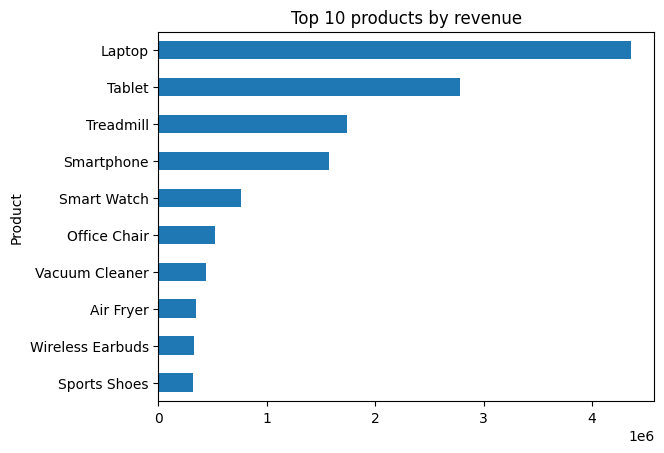

In [39]:
top_products.sort_values().plot(kind="barh", title="Top 10 products by revenue");

## 11. Rank cities by revenue

In [40]:
city_rank = (df.groupby(CITY)[REV].sum()
               .sort_values(ascending=False)
               .to_frame("Revenue"))
city_rank["Rank"] = range(1, len(city_rank) + 1)
city_rank["Share_%"] = city_rank["Revenue"] / city_rank["Revenue"].sum() * 100
city_rank

,Revenue,Rank,Share_%
City,,,
Bengaluru,"3,346,356.59",1,21.45
Delhi,"2,903,658.08",2,18.61
Mumbai,"2,044,805.81",3,13.10
Chennai,"1,973,184.01",4,12.65
Hyderabad,"1,375,487.05",5,8.82
Kolkata,"1,157,262.17",6,7.42
Lucknow,"868,499.80",7,5.57
Pune,"866,929.81",8,5.56
Ahmedabad,"795,305.61",9,5.10


## 12. Monthly revenue and best month

In [41]:
monthly = df.groupby("Month")[REV].sum()
print(monthly)
print(f"\nBest month: {monthly.idxmax()} with revenue {monthly.max():,.2f}")

Month
2025-01   1,126,677.80
2025-02   1,240,040.53
2025-03   1,212,786.46
2025-04     951,176.33
2025-05     746,629.36
2025-06   1,146,272.11
2025-07   1,455,680.52
2025-08   1,509,746.68
2025-09     987,014.20
2025-10   1,590,977.66
2025-11   2,029,698.57
2025-12   1,607,225.95
Freq: M, Name: Revenue, dtype: float64

Best month: 2025-11 with revenue 2,029,698.57


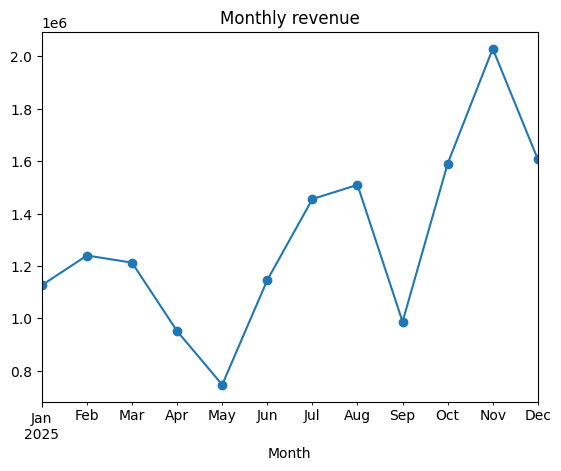

In [42]:
monthly.plot(kind="line", marker="o", title="Monthly revenue");

## 13. Top 10 customers by total spending

In [43]:
top_customers = df.groupby(CUST)[REV].sum().nlargest(10)
top_customers

,Revenue
Customer_ID,
C1201,"660,457.24"
C1121,"616,052.71"
C1089,"411,983.82"
C1040,"345,047.63"
C1241,"253,457.55"
C1116,"236,845.27"
C1098,"236,294.88"
C1093,"225,735.26"
C1153,"221,949.53"


## 14. Payment methods: number of orders and revenue

In [44]:
payment = (df.groupby(PAY)
             .agg(Orders=(ORDER, "nunique"), Revenue=(REV, "sum"))
             .sort_values("Revenue", ascending=False))
payment["Avg_Revenue_per_Order"] = payment["Revenue"] / payment["Orders"]
payment

,Orders,Revenue,Avg_Revenue_per_Order
Payment_Method,,,
UPI,441,"5,979,912.68","13,559.89"
Credit Card,260,"3,365,697.82","12,944.99"
Cash on Delivery,165,"2,148,546.32","13,021.49"
Debit Card,169,"1,957,382.96","11,582.15"
Net Banking,89,"1,147,351.86","12,891.59"
Wallet,76,"1,005,034.53","13,224.14"


## 15. Unusually large order values (IQR method)

In [45]:
q1, q3 = df[REV].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

outliers = df[(df[REV] < low) | (df[REV] > high)]
print(f"Q1={q1:,.2f}  Q3={q3:,.2f}  IQR={iqr:,.2f}")
print(f"Bounds: {low:,.2f} to {high:,.2f}")
print(f"Outlier orders: {len(outliers)} ({len(outliers)/len(df):.1%} of rows)")
print(f"Revenue from outliers: {outliers[REV].sum():,.2f} ({outliers[REV].sum()/df[REV].sum():.1%} of total)")

Q1=1,935.87  Q3=10,738.63  IQR=8,802.76
Bounds: -11,268.26 to 23,942.77
Outlier orders: 164 (13.7% of rows)
Revenue from outliers: 10,142,012.80 (65.0% of total)


In [46]:
outliers.sort_values(REV, ascending=False).head(10)

,Order_ID,Order_Date,Customer_ID,Product,Category,City,Quantity,Unit_Price,Payment_Method,Revenue,Month,Weekday,Calc_Revenue
224,ORD10672,2025-03-17,C1089,Laptop,Electronics,Bengaluru,5,"59,675.28",UPI,"298,376.40",2025-03,Monday,"298,376.40"
545,ORD10569,2025-07-16,C1040,Laptop,Electronics,Bengaluru,4,"59,291.35",Credit Card,"237,165.40",2025-07,Wednesday,"237,165.40"
377,ORD11009,2025-05-18,C1116,Laptop,Electronics,Kolkata,4,"59,068.79",Wallet,"236,275.16",2025-05,Sunday,"236,275.16"
509,ORD11065,2025-07-03,C1201,Laptop,Electronics,Lucknow,4,"51,472.86",UPI,"205,891.44",2025-07,Thursday,"205,891.44"
1003,ORD10439,2025-11-20,C1136,Laptop,Electronics,Ahmedabad,3,"58,640.69",UPI,"175,922.07",2025-11,Thursday,"175,922.07"
119,ORD10495,2025-02-09,C1064,Laptop,Electronics,Chennai,3,"52,360.36",Net Banking,"157,081.08",2025-02,Sunday,"157,081.08"
1057,ORD10760,2025-11-29,C1241,Laptop,Electronics,Kolkata,3,"51,278.75",Debit Card,"153,836.25",2025-11,Saturday,"153,836.25"
666,ORD10259,2025-08-24,C1071,Laptop,Electronics,Bengaluru,3,"51,157.26",Credit Card,"153,471.78",2025-08,Sunday,"153,471.78"
27,ORD11183,2025-01-10,C1149,Treadmill,Sports & Fitness,Delhi,4,"31,745.19",UPI,"126,980.76",2025-01,Friday,"126,980.76"
555,ORD11050,2025-07-20,C1121,Treadmill,Sports & Fitness,Chennai,4,"30,441.51",Credit Card,"121,766.04",2025-07,Sunday,"121,766.04"


## 16. Product-category summary (groupby)

In [47]:
category_summary = (df.groupby(CAT)
                      .agg(Revenue=(REV, "sum"),
                           Quantity=(QTY, "sum"),
                           Orders=(ORDER, "nunique"),
                           Avg_Revenue=(REV, "mean"))
                      .sort_values("Revenue", ascending=False))
category_summary["Share_%"] = category_summary["Revenue"] / category_summary["Revenue"].sum() * 100
category_summary

,Revenue,Quantity,Orders,Avg_Revenue,Share_%
Category,,,,,
Electronics,"9,988,959.69",550,287,"34,804.74",64.02
Sports & Fitness,"2,173,376.01",304,157,"13,843.16",13.93
Home & Kitchen,"1,411,140.61",488,245,"5,759.76",9.04
Clothing,"1,118,742.41",554,264,"4,237.66",7.17
Books & Stationery,"633,141.20",290,114,"5,553.87",4.06
Beauty,"278,566.25",283,133,"2,094.48",1.79


## 17. NumPy: mean, median and standard deviation of order revenue

In [48]:
r = df[REV].to_numpy()
print(f"Mean  : {np.mean(r):,.2f}")
print(f"Median: {np.median(r):,.2f}")
print(f"Std   : {np.std(r, ddof=1):,.2f}  (sample)")

Mean  : 13,003.27
Median: 3,754.14
Std   : 25,310.69  (sample)


## Extra: weekday pattern

In [49]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df.groupby("Weekday")[REV].sum().reindex(order)

,Revenue
Weekday,
Monday,"1,886,781.87"
Tuesday,"1,917,360.95"
Wednesday,"1,934,458.67"
Thursday,"2,537,371.81"
Friday,"1,841,180.72"
Saturday,"2,629,704.05"
Sunday,"2,857,068.10"


## 18. Five business recommendations
Fill these in after running the cells above, citing the specific figures:

1. **Products:**
2. **Cities:**
3. **Seasonality / timing:**
4. **Customers:**
5. **Payments / data quality:**